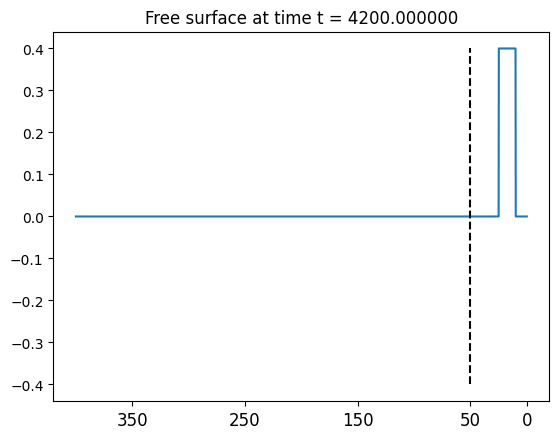

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import sqrt

phi = lambda x: 1 if -10000 > x and x > -25000 else 0
x_max = -400000 # max x-value in meters
dx = 200 # mesh width in meters
g = 9.81 # gravitational acceleration
t_f = 4200 # end time
number_of_cells = abs(int(x_max/dx))
domain = np.linspace(start=0, stop=x_max, num=number_of_cells)

b_x = lambda x: -4000 if -50000 >= x else -200 # bathymetry defining function
b = np.array([b_x(x) for x in domain]) # bathymetry array
h = np.array([phi(x) * 0.4 - b_x(x) for x in domain]) # water height array
hu = np.zeros(number_of_cells) # water momentum array

# update arrays
h_left_up = np.zeros(number_of_cells)
h_right_up = np.zeros(number_of_cells)
hu_left_up = np.zeros(number_of_cells)
hu_right_up = np.zeros(number_of_cells)

def plot_graph(domain, h, b, t=-1):
    plt.plot(domain, h+b)
    plt.plot([-50000,-50000], [-0.4,0.4], 'k--')
    plt.xticks([-350000,-250000,-150000, -50000, 0],['350','250','150','50','0'],fontsize=12)
    plt.title("Free surface at time t = %f" % t)
    plt.show()

plot_graph(domain, h, b, 4200)

In [2]:
# solver
def compute_net_updates(h_l, h_r, hu_l, hu_r, b_l, b_r):
    if b_r >= 0 and b_l >= 0:
        return (0, 0, 0, 0, 0)
    if b_r >= 0 and b_l < 0:
        h_r = h_l
        hu_r = -hu_l
        b_r = b_l
    if b_r < 0 and b_l >= 0:
        h_l = h_r
        hu_l = -hu_r
        b_l = b_r

    if h_l == h_r and b_l == b_r and hu_l == hu_r:
        # steady state
        return (0, 0, 0, 0, 0)

    #############################################################################################
    # The following code is taken from:                                                         #
    # https://github.com/BrisaDavis/adjoint/releases/tag/paper1_aspublished                     #
    # file rp1_geoclaw_adjoint.f                                                                #
    # or                                                                                        #
    # https://github.com/BrisaDavis/adjoint/blob/adjoint_amr/src/riemann/rpn2_geoclaw_adjoint.f #
    #############################################################################################

    hLhat = -b_l
    hRhat = -b_r

    cL = sqrt(g * hLhat) # linearized speed left
    cR = sqrt(g * hRhat) # linearized speed right

    # f-wave splitting
    delta = np.zeros(3)
    delta[0] = -hu_r * cR**2 + hu_l * cL**2
    delta[1] = -(h_r + b_r) + (h_l + b_l)
    delta[2] = 0

    beta = np.zeros(3)
    beta[0] = (delta[0] + cR * delta[1]) 
    beta[1] = (-delta[0] + cL * delta[1])
    beta[2] = delta[2]
    if (cL + cR) != 0:
        beta[0] = beta[0] / (cL + cR)
        beta[1] = beta[1] / (cL + cR)

    # compute waves
    fw = np.zeros((2,2)) # f-waves
    sw = np.zeros(2) # wave speeds

    fw[0][0] = cL * beta[0]
    fw[1][0] = beta[0]
    sw[0] = -cL

    fw[0][1] = -cR * beta[1]
    fw[1][1] = beta[1]
    sw[1] = cR

    amdq = np.zeros(2) # left going flux
    apdq = np.zeros(2) # right going flux

    # determine  left and right going fluxes
    for i in [0, 1]:
        if sw[i] < 0:
            amdq = amdq + fw.T[i]
        elif sw[i] > 0:
            apdq = apdq + fw.T[i]
        else:
            amdq = amdq + 0.5 * fw.T[i]
            apdq = apdq + 0.5 * fw.T[i]

    #########################################################################
    
    amdq = fw.T[0]
    apdq = fw.T[1]
    
    return (amdq[0], amdq[1], apdq[0], apdq[1], max(abs(sw)))

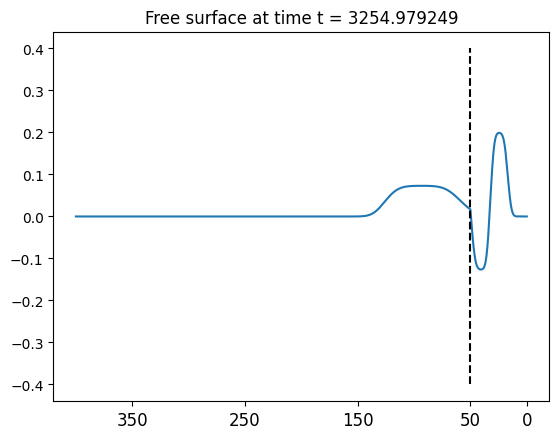

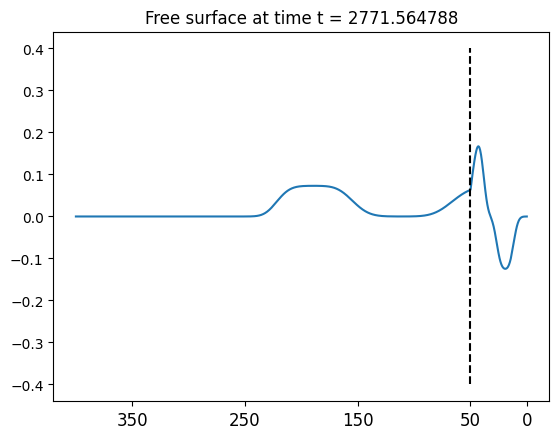

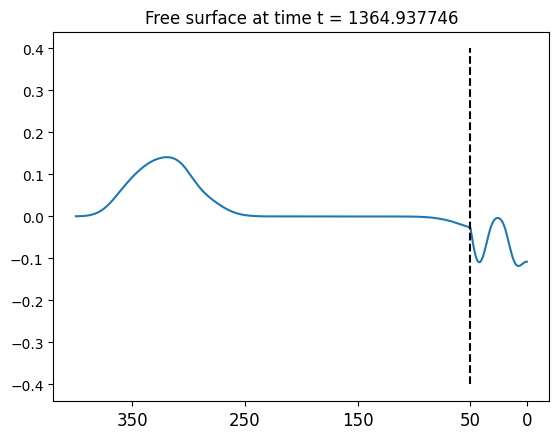

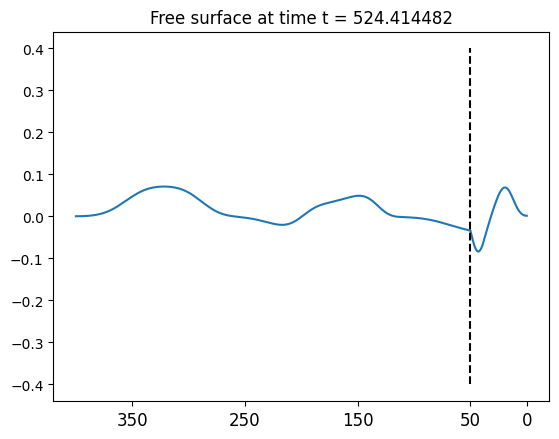

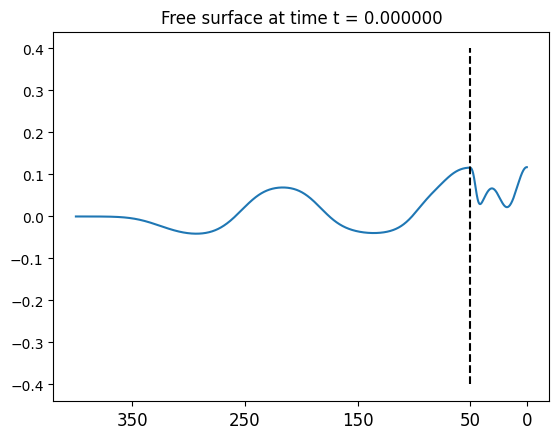

In [3]:
t = 0
# Visualization variables:
eta_values = []
t_values = []
t_count = 0

while t < t_f:
    if t_count == 0 and t >= 4200 - 3255:
        plot_graph(domain, h, b, t_f - t)
        t_count = t_count + 1
    elif t_count == 1 and t>= 4200 - 2772:
        plot_graph(domain, h, b, t_f - t)
        t_count = t_count + 1
    elif t_count == 2 and t >= 4200 - 1365:
        plot_graph(domain, h, b, t_f - t)
        t_count = t_count + 1
    elif t_count == 3 and t >= 4200 - 525:
        plot_graph(domain, h, b, t_f - t)
        t_count = t_count + 1
    h[0] = h[1]
    hu[0] = 0.0
    h[-1] = h[-2]
    hu[-1] = 0.0
    
    eta_values.append([abs(eta) for eta in h+b])
    t_values.append(t)
    max_wave_speed = 0
    # calculate fluxes
    for i in range(1, len(h)):
        h_left_up[i-1], hu_left_up[i-1], h_right_up[i-1], hu_right_up[i-1], edge_speed = compute_net_updates(h[i-1], h[i], hu[i-1], hu[i], b[i-1], b[i])
        max_wave_speed = max(max_wave_speed, edge_speed)
    
    max_time_step = dx / max_wave_speed * 0.9

    # wave propagation
    # https://www.clawpack.org/wp_algorithms.html?highlight=godunov%20splitting
    for i in range(1, len(h)):
        h[i] -= max_time_step / dx * (h_right_up[i-1] + h_left_up[i])
        hu[i] -= max_time_step / dx * (hu_right_up[i-1] + hu_left_up[i])

    h[0] = h[1]
    hu[0] = 0.0
    h[-1] = h[-2]
    hu[-1] = 0.0
   
    t = t + max_time_step

t_values.append(t)
eta_values.append([abs(eta) for eta in h+b])
plot_graph(domain, h, b, 0)

In [4]:
# Visualize to compare with paper
from PIL import Image
img = Image.new(mode="RGB", size=(number_of_cells, len(t_values)))
for i in range(0, len(t_values)):
    for j in range(0, number_of_cells):
        img.putpixel((j,i), (0,255,0) if eta_values[i][number_of_cells - 1 - j]==0.1 else (255,255,255))
img.show()

Text(0, 0.5, 'Hours')

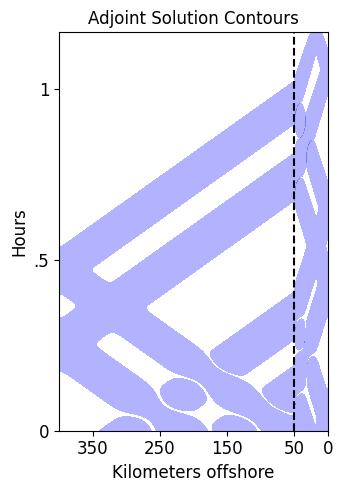

In [7]:
from pylab import * 
tmax = t_values[-1]
Xa = domain
Ta = t_values
eta_values.reverse()
etaanorm = eta_values
textsize = 12
size = 12
axes([0.08,0.09,0.42,0.83])
contourf(Xa,Ta,etaanorm,[.01,1e10],colors=['b'],alpha=0.3)
plot([-50000,-50000],[0,tmax],'k--')
title("Adjoint Solution Contours", fontsize=textsize)
yticks([3600, 1800, 0],['1','.5','0'],fontsize=size)
xticks([-350000,-250000,-150000, -50000, 0],['350','250','150','50','0'],fontsize=size)
xlabel("Kilometers offshore",fontsize=textsize)
ylabel("Hours",fontsize=textsize)